# 04 — Training and evaluation

## Setup

In [33]:
import os, sys, pathlib, warnings
root = pathlib.Path.cwd()
if root.name == "notebooks":
    root = root.parent
    os.chdir(root)
sys.path.insert(0, str(root))

# Warnings print the full path of the file that raised them.
warnings.filterwarnings("ignore", module="tqdm")
warnings.filterwarnings("ignore", message=".*IProgress.*")

In [34]:
import yaml, csv, torch, numpy as np, matplotlib.pyplot as plt
from pathlib import Path

cfg = yaml.safe_load(open("configs/default.yaml"))
device = "cuda" if torch.cuda.is_available() else "cpu"

print("device     :", device)
print("train crop :", cfg["train"]["crop_size"], "| batch", cfg["train"]["batch_size"], "| epochs", cfg["train"]["epochs"])
print("eval window:", cfg["evaluate"]["window"], "| stride", cfg["evaluate"]["stride"])

device     : cuda
train crop : 256 | batch 16 | epochs 50
eval window: 512 | stride 256


## Training curves

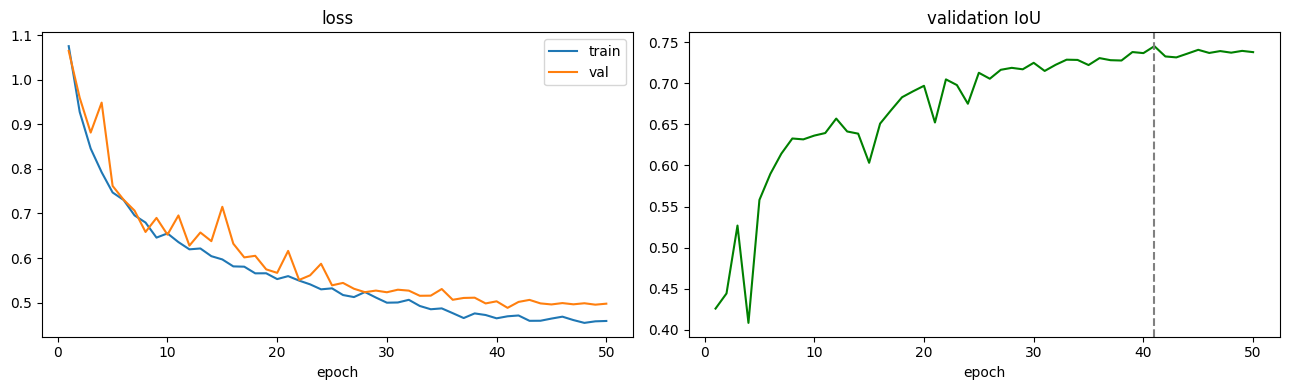

best val IoU 0.7450 at epoch 41 - saved checkpoint


In [35]:
hist = Path("runs/baseline/history.csv")
if hist.exists():
    rows = list(csv.DictReader(open(hist)))
    ep  = [int(r["epoch"]) for r in rows]
    tr  = [float(r["train_loss"]) for r in rows]
    va  = [float(r["val_loss"]) for r in rows]
    iou = [float(r["val_iou"]) for r in rows]
    best = max(range(len(iou)), key=lambda i: iou[i])

    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    ax[0].plot(ep, tr, label="train"); ax[0].plot(ep, va, label="val")
    ax[0].set_xlabel("epoch"); ax[0].set_title("loss"); ax[0].legend()
    ax[1].plot(ep, iou, color="green"); ax[1].axvline(ep[best], ls="--", color="grey")
    ax[1].set_xlabel("epoch"); ax[1].set_title("validation IoU")
    plt.tight_layout(); plt.show()
    print(f"best val IoU {iou[best]:.4f} at epoch {ep[best]} - saved checkpoint")
else:
    print("no runs/baseline/history.csv")

## A short run

Settings: `notebook.short_run` in the config.

In [36]:
from torch.utils.data import DataLoader, Subset
from src.dataset import TileDataset, train_transform, val_transform
from src.losses import BCEDiceLoss
from src.metrics import BinaryMetrics
from src.model import UNet

nb = cfg["notebook"]["short_run"]
for k, v in nb.items():
    print(f"{k:15} {v}")

tiles = Path(cfg["data"]["tiles_dir"])
have_tiles = (tiles / "train" / "images").exists()
if have_tiles:
    train_full = TileDataset(tiles / "train", train_transform(nb["crop_size"], seed=0))
    val_full   = TileDataset(tiles / "val", val_transform(nb["crop_size"]))
    train_set = Subset(train_full, range(min(nb["train_tiles"], len(train_full))))
    val_set   = Subset(val_full, range(min(nb["val_tiles"], len(val_full))))
    train_loader = DataLoader(train_set, batch_size=nb["batch_size"], shuffle=True, drop_last=True)
    val_loader   = DataLoader(val_set, batch_size=nb["batch_size"])
    print("\n", len(train_set), "train tiles,", len(val_set), "val tiles")
else:
    print("no tiles - run: python scripts/make_tiles.py")

crop_size       128
batch_size      8
epochs          3
train_tiles     200
val_tiles       60
base_channels   16
depth           3
learning_rate   0.001

 200 train tiles, 60 val tiles


In [37]:
if have_tiles:
    torch.manual_seed(cfg["seed"])
    net = UNet(base_channels=nb["base_channels"], depth=nb["depth"]).to(device)
    opt = torch.optim.AdamW(net.parameters(), lr=nb["learning_rate"])
    loss_fn = BCEDiceLoss()

    for epoch in range(1, nb["epochs"] + 1):
        net.train(); total = 0.0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad(set_to_none=True)
            loss = loss_fn(net(xb), yb)
            loss.backward(); opt.step()
            total += loss.item()

        net.eval(); mt = BinaryMetrics()
        with torch.no_grad():
            for xb, yb in val_loader:
                mt.update(net(xb.to(device)), yb.to(device))
        print(f"epoch {epoch}  loss {total/len(train_loader):.4f}  val IoU {mt.compute()['iou']:.4f}")

epoch 1  loss 1.4008  val IoU 0.0550
epoch 2  loss 1.2815  val IoU 0.1832
epoch 3  loss 1.2335  val IoU 0.1407


## Sliding window

### Window positions

In [38]:
from src.evaluate import window_starts

starts = window_starts(5000, cfg["evaluate"]["window"], cfg["evaluate"]["stride"])
print("starts :", starts[:4], "...", starts[-2:])
print("count  :", len(starts), "per axis ->", len(starts) ** 2, "windows")

starts : [0, 256, 512, 768] ... [4352, 4488]
count  : 19 per axis -> 361 windows


### Full-image prediction

In [39]:
from src.evaluate import predict_image
from src.dataset import eval_transform
from src.model import build_model, normalization_for
from PIL import Image

ckpt = Path("runs/baseline/best.pt")
raw = Path(cfg["data"]["raw_dir"]) / "data" / "train"
name = "austin1"
pred = truth = None

if ckpt.exists() and (raw / "images" / f"{name}.tif").exists():
    state = torch.load(ckpt, map_location=device, weights_only=True)
    model = build_model(state["config"]["model"]).to(device)
    model.load_state_dict(state["model"])

    image = np.array(Image.open(raw / "images" / f"{name}.tif").convert("RGB"))
    truth = np.array(Image.open(raw / "gt" / f"{name}.tif").convert("L")) > 0
    tensor = eval_transform(*normalization_for(state["config"]["model"]))(image=image)["image"]

    logits = predict_image(model, tensor, cfg["evaluate"]["window"],
                           cfg["evaluate"]["stride"], cfg["evaluate"]["batch_size"], device)
    pred = (torch.sigmoid(logits) > cfg["evaluate"]["threshold"]).numpy()

    mt = BinaryMetrics(cfg["evaluate"]["threshold"])
    mt.update(logits, torch.from_numpy(truth))
    print(name, {k: round(v, 4) for k, v in mt.compute().items()})
else:
    print("needs runs/baseline/best.pt and the raw image")

austin1 {'iou': 0.7694, 'dice': 0.8697, 'precision': 0.8663, 'recall': 0.8731}


## Error map

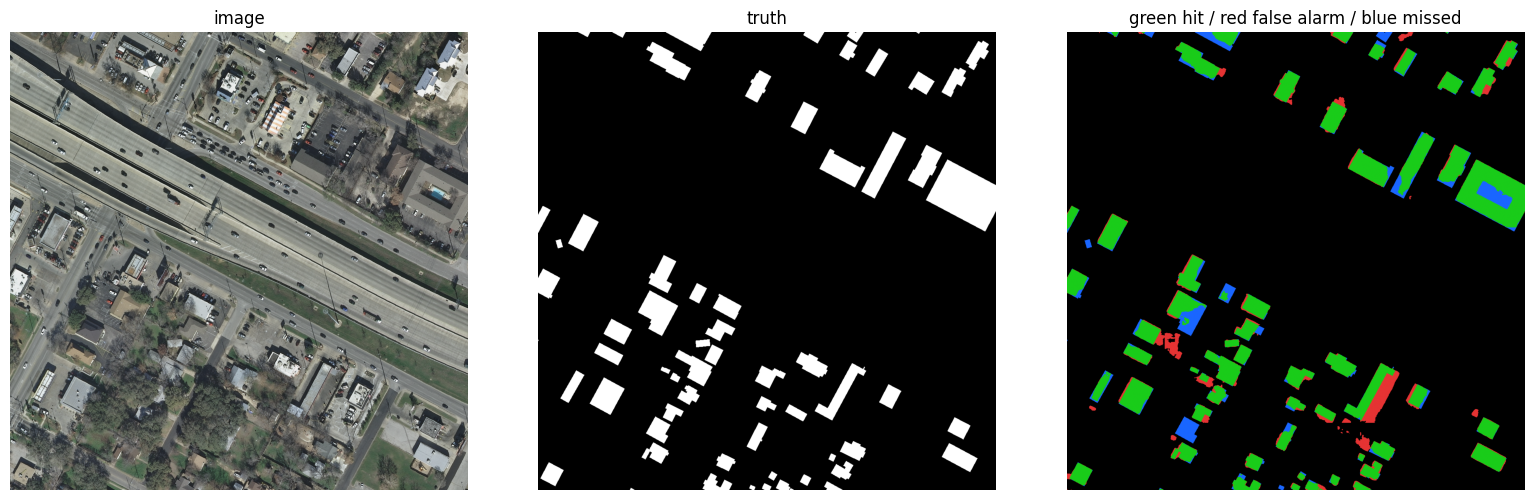

hits 127,826   false alarms 21,101   misses 22,167


In [40]:
if pred is not None:
    s = slice(0, 1200)
    tp =  pred[s, s] &  truth[s, s]
    fp =  pred[s, s] & ~truth[s, s]
    fn = ~pred[s, s] &  truth[s, s]

    overlay = np.zeros((*tp.shape, 3))
    overlay[tp] = [0.1, 0.8, 0.1]
    overlay[fp] = [0.9, 0.2, 0.2]
    overlay[fn] = [0.1, 0.4, 1.0]

    fig, ax = plt.subplots(1, 3, figsize=(16, 5))
    ax[0].imshow(image[s, s]);              ax[0].set_title("image")
    ax[1].imshow(truth[s, s], cmap="gray"); ax[1].set_title("truth")
    ax[2].imshow(overlay);                  ax[2].set_title("green hit / red false alarm / blue missed")
    for a in ax: a.axis("off")
    plt.tight_layout(); plt.show()
    print(f"hits {tp.sum():,}   false alarms {fp.sum():,}   misses {fn.sum():,}")